# 02-GD32 Flash结构与读写实战


## 1. 本篇内容与实验起点

本篇按课程顺序整理以下三段视频，配套讲义为 `OTA远程升级.pdf` 第 **21—30 页**，页码按 PDF 物理页序号计算。

| 视频 | 播放器显示时长 | 本篇对应内容 |
|---|---|---|
| `02_GD32的Flash结构与读写实战_理论知识.mp4` | 10:17 | FMC、扇区结构、Flash 物理特性和擦写步骤 |
| `03_GD32的Flash结构与读写实战_基础操作.mp4` | 15:59 | 字符串、字节数组、断电保持和 Memory 窗口验证 |
| `04_GD32的Flash结构与读写实战_读改写机制.mp4` | 4:51 | 修改少数字节并写回，纠正实验的初始数据 |

资料来自[课程百度网盘](https://pan.baidu.com/s/19vzB65qjPtH6BEy0EBZ5VQ?pwd=1234)，提取码 `1234`。已读取三段视频的完整中文字幕，对照讲义原图，并审阅 `Code.zip` 中的 `02_GD32F407_Flash` 工程。字幕中的函数名以源码为准。

本课使用 **GD32F407VET6，片上 Flash 为 512 KB**。实验承接上一篇已验证的串口／LED 模板工程；配套的最终工程为 `02_GD32F407_Flash/Project/GD32F407.uvprojx`。下文保留课堂操作和源码，不在本机执行烧录；串口、调试和断电现象均指课堂演示。

OTA 最终需要把收到的新固件写入 Flash。本篇先解决“Flash 如何读、如何擦、如何写、怎样修改已有数据”，为后续升级程序准备存储基础。


## 2. FMC、Sector 与 Page 分别是什么

**FMC（Flash Memory Controller，片上闪存控制器）**负责控制 Flash 的擦除、编程等操作。课程把 Flash 比作储物柜，把 FMC 比作管理柜子的“管家”：程序发出操作要求，控制器按照硬件规则完成存储操作。

Flash 中的地址指向具体存储位置。课程用“小格子”表示一个字节，用扇区或页表示更大的管理单位：

| 名称 | 本课中的理解 | 操作时要确认的条件 |
|---|---|---|
| 字节（Byte） | 保存一个 8 位数据的位置 | 字节地址，以及本次读写的数据长度 |
| 扇区（Sector） | 较大的 Flash 区域 | 本型号每个扇区的地址范围和容量 |
| 页（Page） | 某些型号支持的更细粒度单位 | 该型号是否支持页擦除，页大小是多少 |

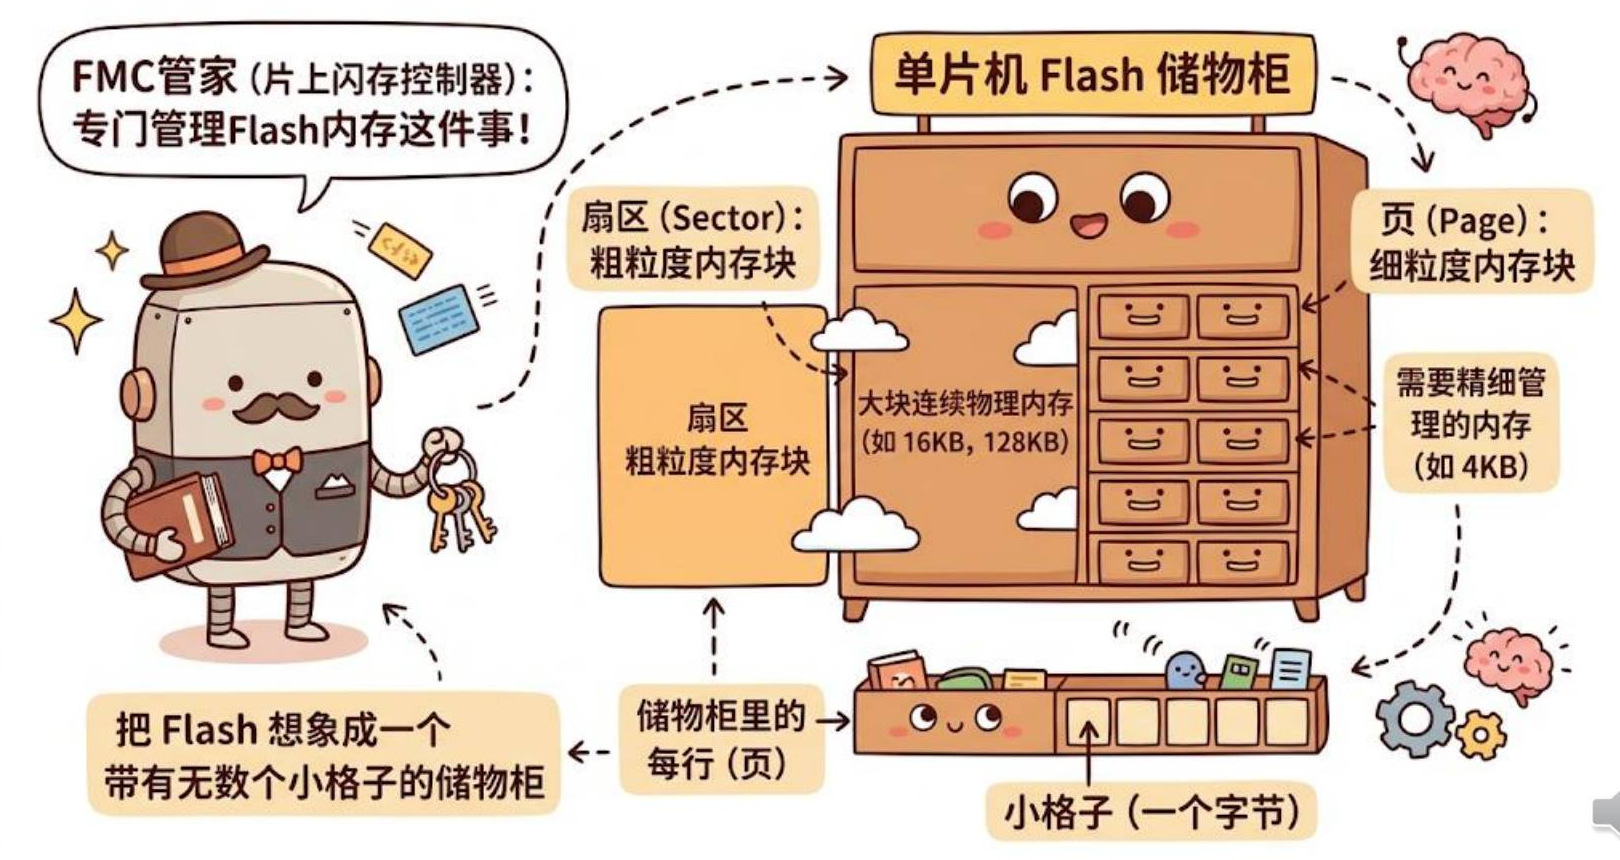

*讲义第 23 页：储物柜用于帮助理解存储单位，具体结构要回到对应芯片手册。*

视频随后查看 `GD32F4xx` 用户手册的 FMC 章节：该系列提供扇区擦除、整片擦除，以及 1、2、4 字节的编程方式；其中页擦除能力与具体型号有关。**本课 GD32F407 的实验按扇区擦除，不能把图中的“4 KB 页”当成它的最小擦除单位。**

源码也体现了这个区别：`FlashErasePage()` 被放在 `GD32F425`、`GD32F427`、`GD32F470` 的条件编译分支内；本篇实际调用的是 `FlashErase()`。


## 3. GD32F407VET6 的 512 KB Flash 如何划分

本课主 Flash 地址范围为 `0x08000000—0x0807FFFF`，共 8 个扇区，**扇区容量并不相同**。

| 扇区 | 起始地址 | 结束地址（包含） | 容量 |
|---|---|---|---|
| Sector 0 | `0x08000000` | `0x08003FFF` | 16 KB |
| Sector 1 | `0x08004000` | `0x08007FFF` | 16 KB |
| Sector 2 | `0x08008000` | `0x0800BFFF` | 16 KB |
| Sector 3 | `0x0800C000` | `0x0800FFFF` | 16 KB |
| Sector 4 | `0x08010000` | `0x0801FFFF` | 64 KB |
| Sector 5 | `0x08020000` | `0x0803FFFF` | 128 KB |
| Sector 6 | `0x08040000` | `0x0805FFFF` | 128 KB |
| Sector 7 | `0x08060000` | `0x0807FFFF` | 128 KB |

容量合计为 `4 × 16 + 64 + 3 × 128 = 512 KB`。因此，“擦除一个扇区”可能擦除 16 KB、64 KB 或 128 KB，取决于目标地址。

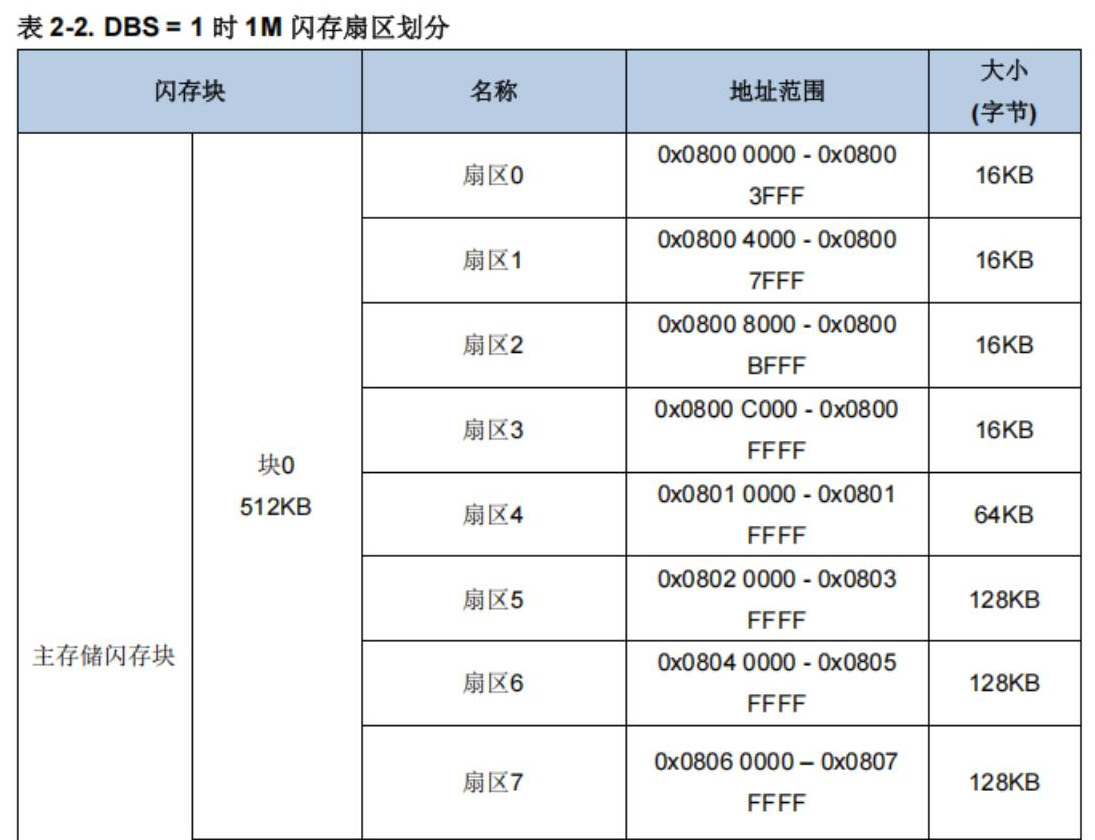

*讲义第 24 页所截手册表的标题为“DBS=1 时 1M 闪存扇区划分”，本图展示其中的块 0、512 KB 部分。不能据此把本课开发板的容量写成 1 MB。配套 Keil 工程的设备为 `GD32F407VE`，IROM 大小配置为 `0x080000`，即 512 KB。*

课程提到的用途包括保存亮度、校准参数等需要断电保留的数据，以及保存 OTA 固件。无论存参数还是程序，都必须先确定可用区域，避免擦除正在使用的代码或其他数据。


## 4. 为什么不能像 RAM 一样直接覆盖

Flash 的编程操作只能把位从 **1 改为 0**，不能靠再次编程把已经为 0 的位恢复成 1。擦除操作会把整个擦除单元恢复为全 1，按字节观察就是 `0xFF`。

因此，需要任意更新已有内容时，通常先擦除，再编程写入。擦除与写入的粒度不同：本课能够逐字节编程，但擦除要作用于整个目标扇区。

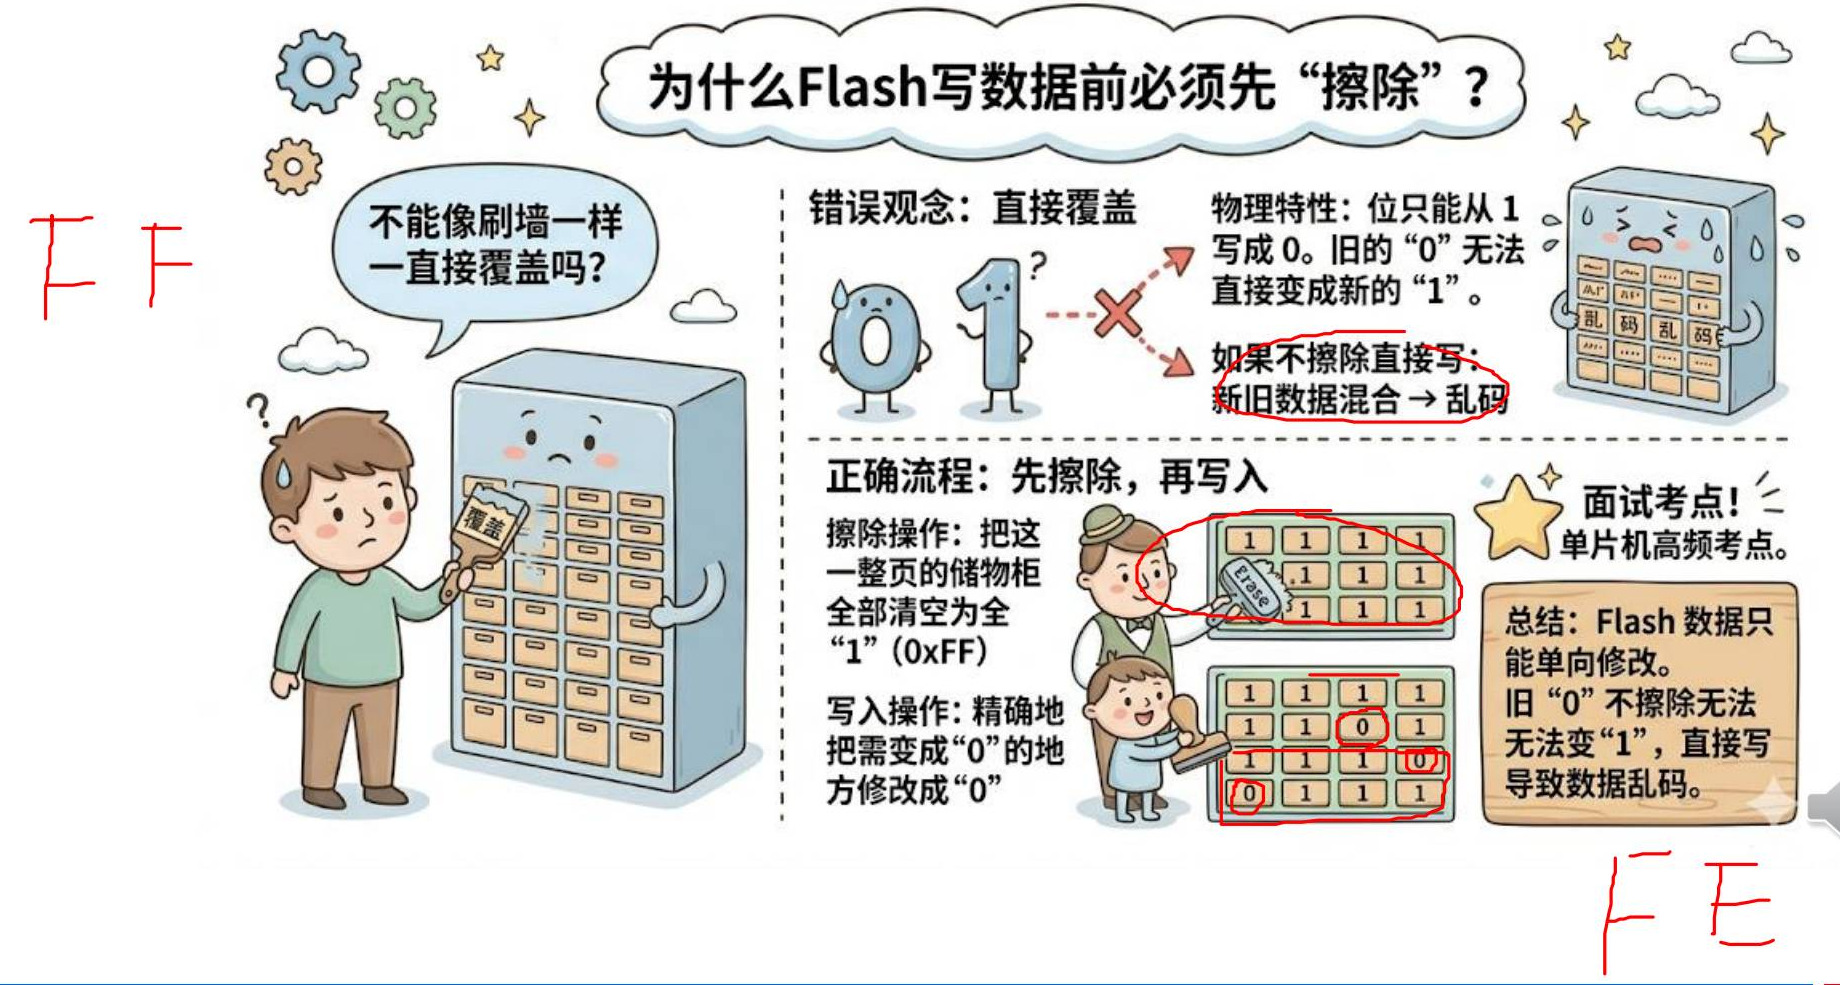

*讲义第 26 页，保留课堂红笔标注。*

**说明用例：**`0xFF` 的二进制为 `11111111`，编程为 `0xFE`（`11111110`）只需把最低位从 1 改为 0；要把它重新变回 `0xFF`，就需要擦除。即使某次改变恰好只有 1→0，也不能据此把任意覆盖写当成通用更新方法。

> “只改两个字节”不等于“只擦两个字节”。擦除会同时清掉该扇区中其他地址的数据，后面的读改写实验就是为了解决这个问题。


## 5. FMC 擦写的四个步骤

课程归纳的顺序是：**解锁 → 擦除 → 编程写入 → 上锁**。

| 步骤 | 作用 | 本课源码中的对应操作 |
|---|---|---|
| 解锁 | 允许修改 Flash，解除控制器写保护 | `fmc_unlock()` |
| 擦除 | 使目标扇区恢复为全 `0xFF` | `fmc_sector_erase()` |
| 编程写入 | 将数据写入已经准备好的 Flash 区域 | `fmc_byte_program()` 等 |
| 上锁 | 完成操作后恢复保护，减少误操作 | `fmc_lock()` |

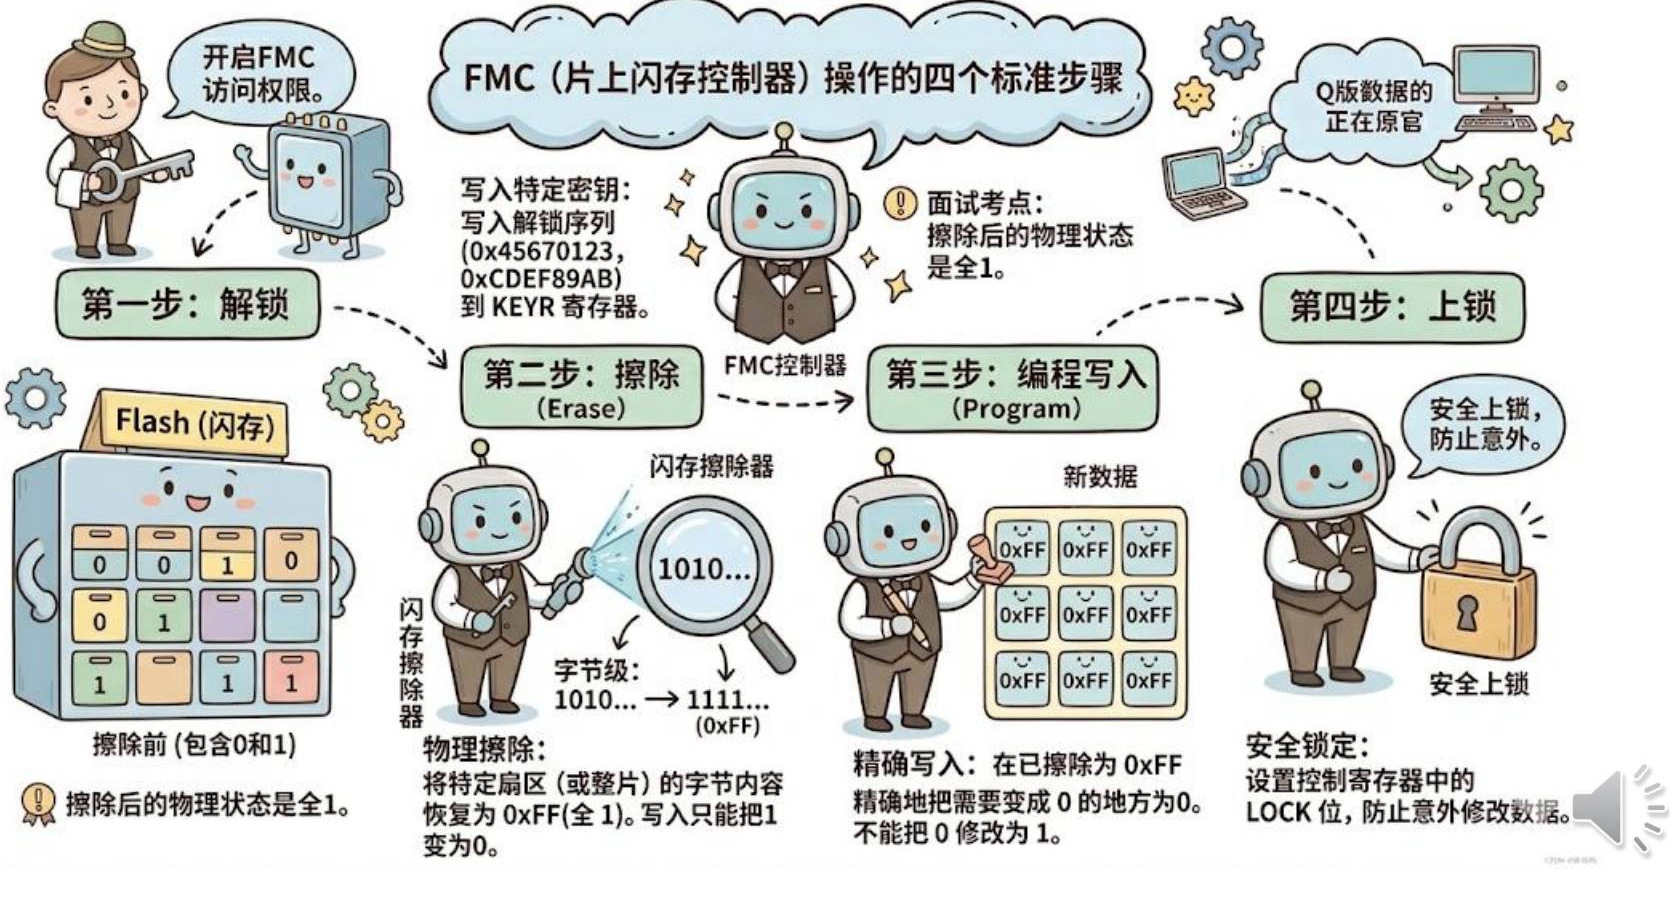

*讲义第 27 页：四步操作示意。图中的寄存器写法用于理解解锁过程，实际编程使用 GD32 库函数。*

解锁不是任意写一个值。配套 GD32 库中的 `fmc_unlock()` 在控制器已锁定时，向 `FMC_KEY` 连续写入 `UNLOCK_KEY0`、`UNLOCK_KEY1`。应用代码直接调用库函数即可，不需要把课件上的 `KEYR` 示意名称照抄成 GD32 寄存器名。

视频还说明，擦除和编程可以分开封装成两次受保护的操作：

```text
擦除：解锁 → 清状态标志 → 擦除扇区 → 上锁
写入：解锁 → 清状态标志 → 逐项编程 → 上锁
```

先擦除再写入的前提不变。没有解锁就尝试擦写，操作可能失败或触发异常；操作完成后应重新上锁。**断电后数据仍保存是 Flash 的非易失性，与最后是否调用上锁函数不是同一件事。**


## 6. 将 Flash 驱动加入模板工程

视频 03 从上一篇的 `01_GD32F407_Hello` 模板开始，把 Flash 驱动加入 `Common` 目录，再在 `main.c` 中调用测试函数。也可以直接打开配套已经完成的 `02_GD32F407_Flash` 工程对照。

本篇涉及的文件如下，路径均相对 `02_GD32F407_Flash/`：

| 文件 | 用途 |
|---|---|
| `Common/flash_drv.h` | 声明读、写、擦除接口和三个测试函数 |
| `Common/flash_drv.c` | 包装 FMC 操作，并实现字符串、数组和读改写实验 |
| `Common/fmc_operation.h`、`Common/fmc_operation.c` | 配套官方示例中的扇区信息查询、编号转换等辅助函数 |
| `User/main.c` | 初始化基础外设，选择本次运行的测试 |
| `Project/GD32F407.uvprojx` | Keil 工程，已加入上述 `.c` 文件 |

若自己从模板添加，除了复制文件，还要把 `flash_drv.c`、`fmc_operation.c` 加入 Keil 工程的 `Common` 组，并确认 C/C++ 头文件路径包含 `..\Common`。最终配套工程已有这些配置。

`User/main.c` 增加头文件，并在串口初始化之后、主循环之前打印启动提示和调用测试。字符串实验阶段只启用一个测试：

```c
#include "flash_drv.h"

/* 放在 USART_init() 等基础初始化之后、while (1) 之前 */
printf("Flash Test\r\n");
FlashDrvTestStr();
```

主循环仍保留原来的 LED 翻转。测试函数位于循环外，每次复位执行一遍，便于把一次启动与一组串口日志对应起来。

| 测试函数的实际名称 | 对应实验 |
|---|---|
| `FlashDrvTestStr()` | 写入和读取字符串 |
| `FlashDrvTest()` | 写入、读取、逐字节比较数组 |
| `FlashDrvTestModity()` | 读出、修改、擦除、写回 |

最后一个函数在原代码中拼写就是 `Modity`，调用时保留实际名称。课堂不同阶段切换调用；源码包中的最终 `main.c` 已启用数组测试，再启用修改测试。


## 7. 先选测试地址，再确定长度

课堂选择 **Sector 1 的起始地址 `0x08004000`** 作为测试区域。Sector 0 从 `0x08000000` 开始保存本次运行的程序，不能直接拿来做擦除实验。

`Common/flash_drv.c` 的最终版本中有以下定义：

```c
#define BUFFER_SIZE                   50

//#define FLASH_TEST_ADDRESS            0x0807F004
#define FLASH_TEST_ADDRESS            0x08004000

uint8_t bufferWrite[BUFFER_SIZE];
uint8_t bufferRead[BUFFER_SIZE];
```

视频先用 `BUFFER_SIZE = 100` 做数组测试，后来在调试阶段改为 `50`；源码包保留的是后一个状态。`bufferWrite` 用于准备待写内容，`bufferRead` 用于接收实际读出的内容，二者是独立的 RAM 数组。

视频编译时观察到程序约占用 **7.07 KB Flash**，仍位于最前面的 16 KB 扇区，因此本次能用下一个扇区存数据。这只是课堂当次构建结果。

> 自己编译时仍要查看实际链接／下载范围，确认程序和常量没有延伸到 `0x08004000`。地址被定义成测试地址，并不会自动把它从链接器的代码区域中保留下来。

`FlashErase(FLASH_TEST_ADDRESS, BUFFER_SIZE)` 的第二个参数用于确定要覆盖的地址范围，**并不表示硬件只擦除 50 或 100 字节**。即使地址只落在扇区中间，底层仍擦掉整个扇区；范围跨扇区时还会擦除多个扇区。


## 8. 实验一：写入并读取字符串

先在 `User/main.c` 调用 `FlashDrvTestStr()`，进入 `Common/flash_drv.c` 查看实现。下面是配套源码中的完整测试函数：

```c
void FlashDrvTestStr(void)
{

  printf("开始擦除写入字符串：\n");
    
  if (!FlashErase(FLASH_TEST_ADDRESS, BUFFER_SIZE)){
    printf("Flash擦除数据故障，请排查！\n");
    return;
  }

  if (!FlashWrite8bit(FLASH_TEST_ADDRESS, (uint8_t*)"Hello itheima", 13)){
    printf("Flash写数据故障，请排查！\n");
    return;
  }

  printf("开始读取\n");
  if (!FlashRead(FLASH_TEST_ADDRESS, bufferRead, 13)){
    printf("Flash读数据故障，请排查！\n");
    return;
  }
  
  bufferRead[13] = '\0'; // 添加字符串结尾标记
	
  printf("\nFlash写入读取结果：%s\n", bufferRead);
}
```

这段代码依次完成：

1. 擦除测试地址对应的扇区，检查返回值；失败就打印提示并返回。
2. 用 `FlashWrite8bit()` 写入 `Hello itheima` 的 **13 个可见字符**，其中包括一个空格。
3. 用 `FlashRead()` 读回 13 个字节，放进另一个数组 `bufferRead`。
4. 在 RAM 数组的索引 `13` 处补上 `\0`，再用 `%s` 打印字符串。

**13 不包含字符串结束符。** 此处只向 Flash 写入 13 字节，结束符是读回后补在 RAM 中的，因此接收缓冲至少要有 14 字节；本课 50 或 100 字节的缓冲均满足。

在 Keil 编译、下载到开发板，打开 `XCOM.exe` 对应串口后复位。课堂接收到启动提示 `Flash Test`，随后读取结果中出现 `Hello itheima`，说明字符串读写链路已经跑通。

这里的 `%s` 输出是本次字符串实验的验证方法。数组实验会进一步检查每一个字节，避免只根据“没有报错”判断读写正确。


## 9. 实验二：写入 100 字节，再逐字节比较

在 `User/main.c` 注释字符串测试，改为调用 `FlashDrvTest()`。视频先把 `BUFFER_SIZE` 设为 **100**，于是循环生成十进制 1—100，即十六进制 **`0x01—0x64`**。

以下为配套源码中的完整函数，实验长度取决于前面的宏：

```c
void FlashDrvTest(void)
{

  printf("准备数据：\n");
  for (uint16_t i = 0; i < BUFFER_SIZE; i++){
    bufferWrite[i] = i + 1;
    printf("0x%02X ", bufferWrite[i]);
  }
  printf("\n开始擦除\n");
  if (!FlashErase(FLASH_TEST_ADDRESS, BUFFER_SIZE)){
    printf("Flash擦除数据故障，请排查！\n");
    return;
  }

  printf("\n开始写入\n");
  if (!FlashWrite8bit(FLASH_TEST_ADDRESS, bufferWrite, BUFFER_SIZE)){
    printf("Flash写数据故障，请排查！\n");
    return;
  }

  printf("\n开始读取\n");
  if (!FlashRead(FLASH_TEST_ADDRESS, bufferRead, BUFFER_SIZE)){
    printf("Flash读数据故障，请排查！\n");
    return;
  }
	
  for (uint16_t i = 0; i < BUFFER_SIZE; i++){
    // 把读到的字节逐个进行比较
    if (bufferRead[i] != bufferWrite[i]) {
      printf("0x%02X ", bufferRead[i]);
      printf("Flash测试故障，请排查！\n");
      return;
    }
    printf("0x%02X ", bufferRead[i]);

  }
  printf("\nFlash测试通过！\n");
}
```

先在 `bufferWrite` 中准备数据，再擦除 Flash、写入、读取到 `bufferRead`。最后比较的是两个不同数组：

```c
bufferRead[i] != bufferWrite[i]
```

发现任一字节不一致，打印该字节及故障提示并提前返回；全部相同，才会到达 `Flash测试通过！`。`%02X` 按至少两位十六进制输出，字节之间加空格，方便核对。

| 本次操作 | 课堂应观察的位置与结果 |
|---|---|
| 编译、烧录，清空旧串口日志后复位 | 先出现 `Flash Test` |
| 观察“准备数据” | 从 `0x01` 连续到 `0x64`，共 100 字节 |
| 观察读取与比较结果 | 同样从 `0x01` 到 `0x64`，最后打印测试通过 |

若使用源码包默认的 `BUFFER_SIZE = 50`，结束值会是 `0x32`，这是长度不同造成的正常差异。不要拿 50 字节配置期待 `0x64`。

课程还指出，当前使用的 `FlashWrite8bit()` 一次编程一个字节；另有 `FlashWrite16bit()` 接收 `uint16_t` 数组，一次编程一个半字（2 字节），其写地址需要 2 字节对齐。后一接口的长度参数按半字个数理解，不能直接套用字节接口的计数。


## 10. 实验三：验证 Flash 断电后仍保存数据

如果每次启动都先写入，再读取，即使读对了，也没有独立验证“以前保存的内容是否还在”。视频因此保留已经成功写入的数据，暂时取消后续启动中的擦写操作。

在 `Common/flash_drv.c` 的 `FlashDrvTest()` 中，**把擦除和写入的两个完整判断块注释掉**，包括其中的错误处理，保留准备数组、读取、比较与打印部分。不要只注释函数调用而留下空的 `if` 条件或仍在运行的 `return`。

操作顺序如下：

1. 先运行上一节完整测试，把 `0x01—0x64` 成功保存到测试区域。
2. 注释本次启动的擦除、写入，重新编译和下载。
3. 复位，只读取原区域，与 RAM 中重新生成的预期数组比较；课堂仍然通过。
4. 开发板断电，再上电，重新打开串口；必要时再按一次复位，避免错过串口打开前已经发出的启动日志。
5. 再次观察读取和逐字节比较结果，课堂仍然通过。

此时 RAM 中的 `bufferWrite` 是本次启动重新生成的预期值，Flash 中的数据来自之前的写入。两者再次一致，才体现了 Flash 的非易失性。

**补充说明：**这一步依赖课堂下载配置没有把保存测试数据的 Sector 1 一并擦掉。不同下载器／Keil 擦除选项可能执行整片擦除；“下载新程序一定保留测试数据”不是通用保证。若重新下载后数据消失，先检查擦除范围，再分析掉电保持问题。


## 11. 用 Keil Memory 窗口观察“擦成 FF，再写入”

视频约 `10:27` 开始把 `BUFFER_SIZE` 改为 **50**，恢复 `FlashDrvTest()` 内的擦除和写入，使用断点直接查看地址中的数据。此时预期数组为 `0x01—0x32`。

1. 编译后进入 Keil Debug，在 `FlashErase()` 调用前，以及擦除后、写入后的位置设置断点。
2. 打开 Memory 窗口，在地址栏输入 `0x08004000`。
3. 如果窗口按 4 字节一组显示，右键改为按无符号单字节查看，便于与 `0x01`、`0x02` 等逐项对应。
4. 复位并运行到擦除前的断点，先确认旧内容。课堂已有先前写入的数据。
5. 单步执行完擦除调用，再看 Memory：原扇区中的数据变为 `FF`。
6. 单步执行完写入调用，再看 Memory：测试区域出现 `01 02 03 … 32`。

| 停止位置 | Memory 中应核对的内容 |
|---|---|
| 擦除之前 | 上一次已写的数据，具体取决于实验初始状态 |
| 擦除调用已经完成，写入尚未发生 | 连续 `FF`，验证擦除结果 |
| 写入调用已经完成 | 前 50 字节为 `01—32` |

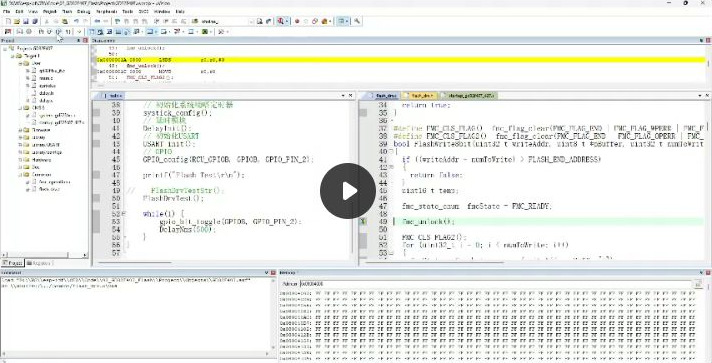

*视频 03 约 `12:48`：程序正在写入函数内、尚未执行逐字节编程，右下方 Memory 窗口显示擦除后的 `FF`。截图用于观察调试状态，函数完整内容以前后源码块为准。*

**黄色执行箭头指向下一条将执行的语句。** 仅仅停在擦除调用这一行，还不能说明擦除已完成；必须执行过调用再检查内存。课堂有一次单步进入函数或跑过观察位置，随后通过重新设断点、复位重走流程完成验证。

用 Memory 窗口可以把“擦除后是 `FF`”“写入后是目标数组”分开观察，比只看最后一条串口通过日志更直观。


## 12. 回到驱动：读、擦、写各自做了什么

视频随后用 F12 进入底层实现。先看 `Common/flash_drv.c` 的读函数：Flash 在处理器地址空间中可以直接读取，所以这里按地址取出字节，再复制到目标 RAM 数组。

```c
bool FlashRead(uint32_t readAddr, uint8_t *pBuffer, uint32_t numToRead)
{
  if ((readAddr + numToRead) > FLASH_END_ADDRESS)
  {
    return false;
  }

  uint32_t addr = readAddr;
  for (uint32_t i = 0; i < numToRead; i++)
  {
    *pBuffer = *((uint8_t *)addr);
    addr = addr + 1;
    pBuffer++;
  }
  return true;
}
```

读操作没有调用解锁、擦除，也没有改变原数据。擦除函数则先解锁、清状态标志，查询起止地址所在的扇区，逐个擦除后上锁：

```c
bool FlashErase(uint32_t eraseAddr, uint32_t numToErase) {
  if (numToErase == 0 || (eraseAddr + numToErase) > FLASH_END_ADDRESS)
  {
    return false;
  }
  fmc_sector_info_struct start_sector_info;
  fmc_sector_info_struct end_sector_info;
  uint32_t sector_num,i;
  /* unlock the flash program erase controller */
  fmc_unlock();
  /* clear pending flags */
  fmc_flag_clear(FMC_FLAG_END | FMC_FLAG_OPERR | FMC_FLAG_WPERR | FMC_FLAG_PGMERR | FMC_FLAG_PGSERR);
  /* get the information of the start and end sectors */
  start_sector_info = fmc_sector_info_get(eraseAddr);
  end_sector_info = fmc_sector_info_get(eraseAddr + numToErase);
  /* erase sector */
  for(i = start_sector_info.sector_name; i <= end_sector_info.sector_name; i++) {
    sector_num = sector_name_to_number(i);
    if(FMC_READY != fmc_sector_erase(sector_num)) {
      goto erase_err;
    }
  }
  /* lock the flash program erase controller */
  fmc_lock();
  return true;

erase_err:
  /* lock the main FMC after the erase operation */
  fmc_lock();
  return false;
}
```

其中，`fmc_sector_info_get()` 和 `sector_name_to_number()` 来自 `Common/fmc_operation.c`：前者查找地址所属扇区，后者转换为 FMC 擦除接口需要的编号。参数只是确定受影响的扇区，真正执行的是 `fmc_sector_erase()`。

字节写入函数逐项调用 `fmc_byte_program()`，检查状态是否为 `FMC_READY`；失败路径也会重新上锁：

```c
bool FlashWrite8bit(uint32_t writeAddr, uint8_t *pBuffer, uint32_t numToWrite)
{
  if ((writeAddr + numToWrite) > FLASH_END_ADDRESS)
  {
    return false;
  }
  uint16_t temp;

  fmc_state_enum  fmcState = FMC_READY;

  fmc_unlock();

  FMC_CLS_FLAG2();
  for (uint32_t i = 0; i < numToWrite; i++)
  {
    fmcState = fmc_byte_program(writeAddr, pBuffer[i]);
    if (fmcState != FMC_READY)
    {
      fmc_lock();
      return false;
    }

    writeAddr ++;
  }

  fmc_lock();
  return true;
}
```

`FMC_CLS_FLAG2()` 在本文件中用于清除 `END`、`OPERR`、`WPERR`、`PGMERR`、`PGSERR` 等状态标志。`FlashWrite8bit()` 自身不擦除，因此不能脱离“目标区域已经合适地擦除”的前提使用。

课程把擦除、写入分别封装，每个函数内部各做一次解锁和上锁。也可以在更外层统一组织解锁→擦除→写入→上锁，减少重复操作；本篇实验先按原接口理解，不改写整套驱动。

**源码核对补充：**这些教学封装并非完整的通用边界检查。上述原代码保留原样，当前地址与 50／100 字节长度没有触及以下边界：

- `FlashErase()` 用 `eraseAddr + numToErase` 查询末扇区；若范围恰好在下一个扇区起点结束，会多选中一个扇区。以“长度为 N 字节”的定义，最后一个有效字节应是 `eraseAddr + N - 1`，且须先确认 N 非零。
- 读写函数用“起始地址 + 长度”与包含式末地址比较，未完整处理下界与整数溢出；16 位写入还应按 `2 × numToWrite` 计算字节范围。推广到其他地址和长度前，需要先修正这些检查。

因此，后面讲“备份并恢复整个扇区”是保存数据的原则，不能不检查这些边界就把 16 KB 直接交给当前擦除封装。


## 13. 修改少数字节：读—改—写机制

视频 04 提出新问题：Flash 已经存了参数，只想修改其中一个或几个字节，其他数据仍要保留。直接擦除会连带清空同扇区的数据，直接覆盖又不满足任意位更新要求，因此引入 **RMW（Read–Modify–Write，读—改—写）**。

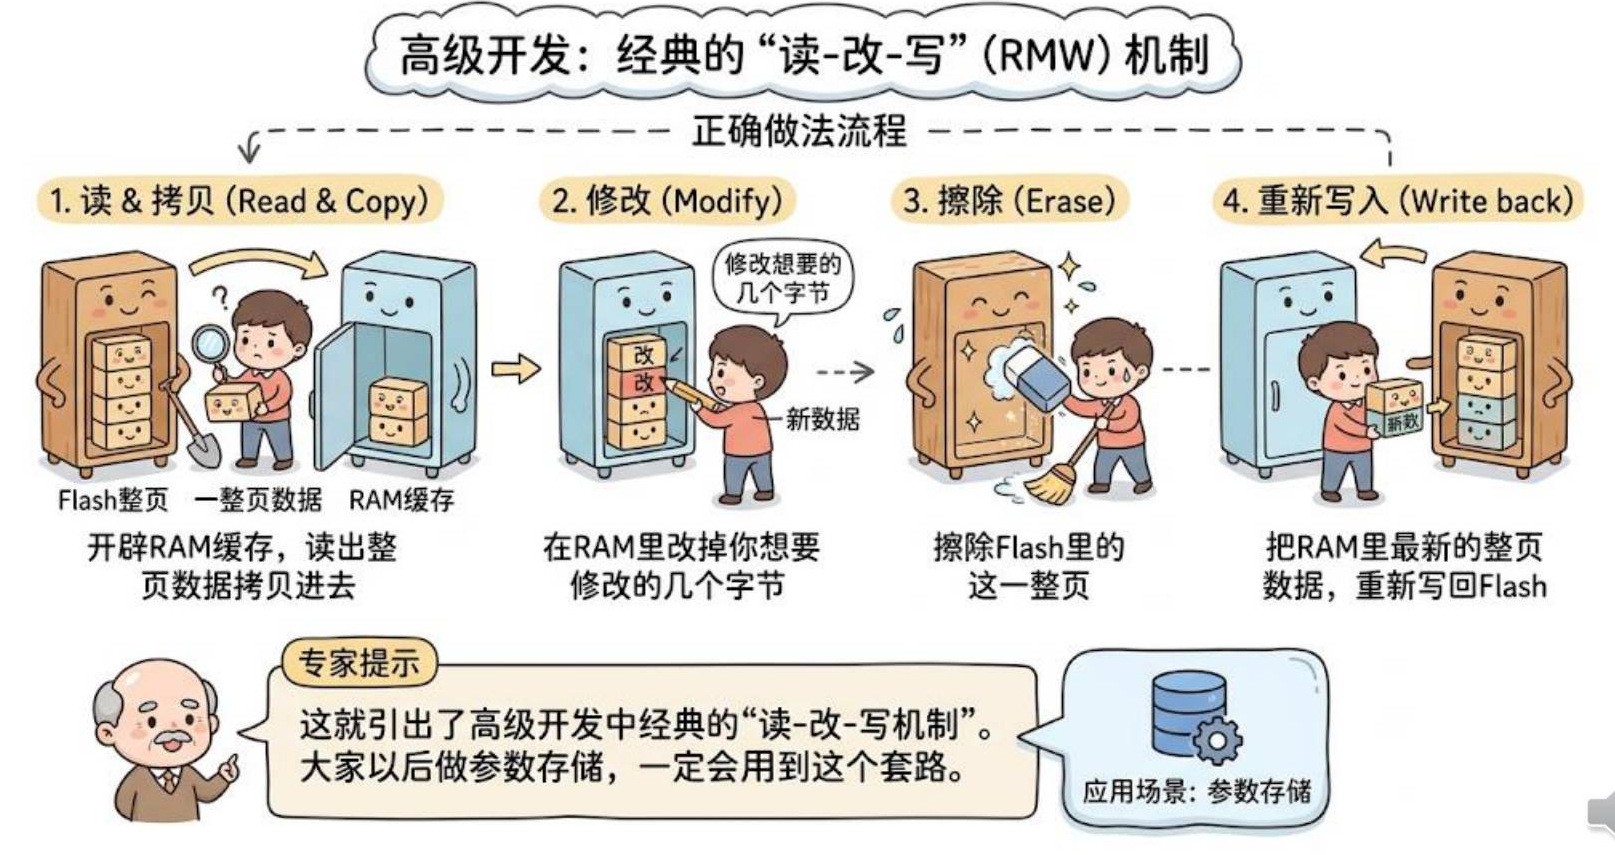

*讲义第 30 页：先把数据搬到 RAM，再修改和写回。图用“页”说明流程，本课硬件应换成实际的扇区擦除单位。*

按 GD32F407 的扇区结构理解，流程是：

1. **读出备份：**先把将被擦除单元中需要保留的数据复制到 RAM。
2. **修改 RAM：**在副本中更改目标字节，其他内容保持不变。
3. **擦除原扇区：**把 Flash 目标扇区恢复为全 `FF`。
4. **写回新内容：**把修改后的副本重新写入 Flash。

这样，小范围的逻辑修改通过“先保存旧内容，再擦除和恢复”完成。Flash 的物理限制没有改变，改变的是程序安排数据的方式。课程指出，后续做参数存储与修改会反复使用这个流程。


## 14. 读改写实验：将索引 3、4 改为 0x33、0x44

`Common/flash_drv.c` 提供 `FlashDrvTestModity()`。本次实验承接前面的 **50 字节**数组，先读出已有数据，在 RAM 中修改索引 `3`、`4`，然后擦除和写回。

```c
void FlashDrvTestModity(void)
{

  printf("开始读取\n");
  if (!FlashRead(FLASH_TEST_ADDRESS, bufferRead, BUFFER_SIZE)){
    printf("Flash读数据故障，请排查！\n");
    return;
  }
  printf("\n开始修改\n");
  bufferRead[3] = 0x33;
  bufferRead[4] = 0x44;
  
  printf("\n开始擦除\n");
  if (!FlashErase(FLASH_TEST_ADDRESS, BUFFER_SIZE)){
    printf("Flash擦除数据故障，请排查！\n");
    return;
  }

  printf("\n开始写入\n");
  if (!FlashWrite8bit(FLASH_TEST_ADDRESS, bufferRead, BUFFER_SIZE)){
    printf("Flash写数据故障，请排查！\n");
    return;
  }

  printf("\n打印修改后的数据: \n");  
  for (uint16_t i = 0; i < BUFFER_SIZE; i++){
    printf("0x%02X ", bufferRead[i]);
  }
  printf("\nFlash测试通过！\n");
}
```

索引从 0 开始，所以 `bufferRead[3]`、`bufferRead[4]` 是第 4、5 个字节，对应地址 `0x08004003`、`0x08004004`。目标变化为：

```text
原数据开头：01 02 03 04 05 06 07 08 … 32
修改后开头：01 02 03 33 44 06 07 08 … 32
```

这组数表示课堂实验的预期变化，不是本机执行输出。

### 先准备初始数据，再做修改

视频第一次直接执行修改函数，发现 `33`、`44` 虽然出现，其他内容却不是期待的连续数组。原因是**没有先把 `01—32` 写进去**，修改函数读取的是 Flash 当时已有的内容。

课堂随后在 `User/main.c` 改为以下顺序，配套源码也保留了这个顺序：

```c
printf("Flash Test\r\n");

//    FlashDrvTestStr();
FlashDrvTest();
FlashDrvTestModity();
```

先确认 `FlashDrvTest()` 的擦除、写入已经恢复且长度为 50，再编译、下载、清理旧日志并复位。第一项测试准备并验证 `01—32`；第二项把第 4、5 字节改成 `33`、`44`，课堂观察到其他位置维持连续数组的内容。

**源码核对补充：**修改函数最后打印的是 RAM 中的 `bufferRead`，没有在写回后再次调用 `FlashRead()`。因此，这条“测试通过”说明程序走完了接口调用与打印流程，不能单凭这行日志声称完成了独立的写后回读比较。要直接确认 Flash 内容，可按前节方法在写入完成后查看 Memory 的 `0x08004000` 区域。

### 50 字节示例能保留多大范围

本函数只备份并写回 `BUFFER_SIZE = 50` 字节，但擦除影响的是 **Sector 1 全部 16 KB**。课堂区域中只有这 50 字节作为本次实验数据，所以可以用它演示步骤；若同扇区其他地址也有有效参数，仅运行这个函数会把那些数据擦掉。

要保证整个扇区的其他数据不丢，需先按实际扇区范围备份完整内容，再修改、正确擦除、完整写回，并先处理前节指出的擦除边界问题。**RAM 备份也不能防止擦除后、写回前突然掉电。** 这是本示例的边界，本课没有实现掉电恢复方案。


## 15. 本篇实验之间的先后关系

| 阶段 | `main.c` 中的测试 | 驱动中的长度／操作 | 验证重点 |
|---|---|---|---|
| 字符串 | `FlashDrvTestStr()` | 写、读 13 字节，RAM 补 `\0` | 串口读取结果为 `Hello itheima` |
| 字节数组 | `FlashDrvTest()` | `BUFFER_SIZE = 100`，启用擦写 | `01—64` 逐字节一致 |
| 复位／断电保持 | `FlashDrvTest()` | 暂停擦除和写入，保留读取比较 | 读取到之前保存的内容 |
| Memory 调试 | `FlashDrvTest()` | 改为 50，恢复擦除和写入 | 擦后 `FF`，写后 `01—32` |
| 读改写 | 先 `FlashDrvTest()`，后 `FlashDrvTestModity()` | 保持 50 字节，先建立基线再修改 | 索引 3、4 为 `33`、`44`，其余示例数据保持 |

本课的主线是：先确认芯片的真实扇区结构，再按 FMC 规则擦写，用串口回读和 Memory 窗口分步验证，最后在 RAM 中完成修改并写回。读写长度、物理擦除范围和测试初始状态必须分别弄清。

完成本篇后，已具备理解后续 Bootloader 如何操作 Flash 的基础；通信接收、固件跳转和完整 OTA 升级流程继续按后续课程展开。
